# RAG Agent (Agentic RAG) com Google Gemini


1. Buscar e pré-processar documentos que serão usados para recuperação.
2. Indexar esses documentos para busca semântica e criar uma ferramenta de recuperação para o agente.
3. Construir um sistema RAG agentic que pode decidir quando usar a ferramenta de recuperação.


## Configuração inicial

Vamos instalar os pacotes necessários e definir as chaves de API. Note que estamos usando o pacote `langchain-google-genai` para integração com o Gemini.

In [1]:
# %%capture --no-stderr
# %pip install -U --quiet langgraph langchain langchain-community langchain-text-splitters langchain-google-genai

In [2]:
import getpass
import os

def _set_env(key: str):
    if key not in os.environ:
        os.environ[key] = getpass.getpass(f"{key}:")

_set_env("GEMINI_API_KEY_RAG")

CHAVE_API_GOOGLE_RAG = os.getenv("GEMINI_API_KEY_RAG")
if CHAVE_API_GOOGLE_RAG:
    os.environ["GOOGLE_API_KEY"] = CHAVE_API_GOOGLE_RAG

## 1. Pré-processar documentos

1. Buscar documentos para usar em nosso sistema RAG. 

In [3]:
from langchain_community.document_loaders import WebBaseLoader

urls = [
    "https://itsmnapratica.com.br/tudo-sobre-itil/",
    "https://www.estrategiaconcursos.com.br/blog/resumo-itil-4-iss-sp/",
    "https://www.ibm.com/br-pt/think/topics/it-infrastructure-library",
    "https://www.ibm.com/br-pt/think/topics/it-infrastructure-library"

]

docs = [WebBaseLoader(url).load() for url in urls]

C:\Users\sirja\AppData\Local\Temp\ipykernel_6640\2173612769.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [4]:
docs[0][0].page_content.strip()[:1000]

'ITIL®: o que é, para que serve e como tirar a certificação – ITSM na Pratica\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\t\t\tPular para o conteúdo\t\t\n\n\n\n\n\n\n\nITSM na Pratica\n\n\n\n\nHome\nCursos\nYoutube\nContato\n \n\n\n \n\n\n\n\n\n\n\n\n\nITSM na Pratica\n\n\n\n\n\n\n\n\n\nMenu de navegação\n\n \n\n \n\n\n\n\n\n\n\n\n\n\n\n\n\n\t\t\tMenu de navegação\t\t\t\t\t\n\n\n\n\n\n\nHome\nCursos\nYoutube\nContato\n \n\n\n \n\n\n\n\n\nITIL®: o que é, para que serve e como tirar a certificação\xa0Renê Chiarijaneiro 31, 202662 comentários\n\n\n\n\nAtualizado em 16/08/2022.\n\xa0\nO ITIL tem sido um dos mais populares frameworks dos últimos 20 anos, servindo como uma referência para as empresas gerenciarem melhor seus serviços habilitados por tecnologia.\nAtualmente é difícil encontrar alguém que nunca tenha ouvido falar sobre ITIL. Seja em um artigo, um comentário na empresa ou uma vaga de TI.\xa0\nMas se você está procurando um conteúdo mais completo sobre este tema, espe

2. Dividir os documentos buscados em partes menores para indexação no nosso banco de dados vetorial:

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

docs_list = [item for sublist in docs for item in sublist]

text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=100, chunk_overlap=50
)
doc_splits = text_splitter.split_documents(docs_list)

In [6]:
doc_splits[0].page_content.strip()

'ITIL®: o que é, para que serve e como tirar a certificação – ITSM na Pratica\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\t\t\tPular para o conteúdo\t\t\n\n\n\n\n\n\n\nITSM na Pratica\n\n\n\n\nHome\nCursos\nYoutube\nContato'

## 2. Criar uma ferramenta de recuperação (recuperador)

Agora que temos os documentos divididos, podemos indexá-los em um banco de dados vetorial que usaremos para busca semântica. Usaremos embeddings do Google Gemini.

In [7]:
# from langchain_core.vectorstores import InMemoryVectorStore
# from langchain_google_genai import GoogleGenerativeAIEmbeddings

# embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-2")

# vectorstore = InMemoryVectorStore.from_documents(
#     documents=doc_splits, embedding=embeddings
# )
# recuperador = vectorstore.as_recuperador()

In [8]:
# %pip install -U sentence-transformers langchain-huggingface

from langchain_core.vectorstores import InMemoryVectorStore
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

vectorstore = InMemoryVectorStore.from_documents(
    documents=doc_splits, embedding=embeddings
)
recuperador = vectorstore.as_retriever()

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2060.07it/s]


2. Criar uma ferramenta de recuperação usando `create_recuperador_tool` do LangChain:

In [9]:
from langchain_core.tools import create_retriever_tool

recuperador_tool = create_retriever_tool(
    recuperador,
    "recuperador_blog_posts",
    "Ferramenta para recuperar informações sobre ITIL a partir de uma coleção de documentos",
)

3. Testar a ferramenta:

In [10]:
recuperador_tool.invoke({"query": "Quais são as principais práticas do ITIL v4?"})

'Dimensões da ITIL 4\nAs quatro dimensões da ITIL 4 são (OP IT PF FP):\n\nAlgumas das principais diferenças são:\n\nVeja a seguir a lista das práticas do ITIL4:\nAs 34 práticas são agrupadas em três categorias:\n\nQuais os elementos chave do ITIL4?\nO modelo conceitual do ITIL4 apresenta 5 elementos principais. São eles:'

## 3. Gerar consulta ou responder

Agora vamos construir os componentes ([nós](../../concepts/low_level.md#nodes) e [arestas](../../concepts/low_level.md#edges)) para o nosso grafo RAG agentic.

Os componentes operarão sobre o `MessagesState` — um estado de grafo que contém uma chave `messages` com uma lista de [mensagens de chat](https://python.langchain.com/docs/concepts/messages/).

1. Construir um nó `gerar_consulta_ou_resposta`. Ele chamará um LLM (Gemini) para gerar uma resposta baseada no estado atual. Dadas as mensagens de entrada, ele decidirá se deve recuperar usando a ferramenta de recuperação ou responder diretamente ao usuário. Note que estamos dando ao modelo de chat acesso à `recuperador_tool` via `.bind_tools`:

In [11]:
from langgraph.graph import MessagesState
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite-preview", temperature=0.3)

def gerar_consulta_ou_resposta(state: MessagesState):
    """Chama o modelo para gerar uma resposta baseada no estado atual.
    Dada a pergunta, decide se deve recuperar usando a ferramenta recuperador ou simplesmente responder ao usuário."""
    response = (
        llm
        .bind_tools([recuperador_tool]).invoke(state["messages"])
    )
    return {"messages": [response]}

In [12]:
# Instruções, prompts e utilitários adaptados do notebook `itil_rag_adaptativo`
instrucao = """<role>
Você é um Especialista em ITIL 4 e um planejador estratégico com alto poder de raciocínio.
Sua função é atuar como um consultor para Gestores de TI.
Você é incisivo, analítico e extremamente rigoroso na aplicação das diretrizes da ITIL 4.
Seu objetivo é analisar bases de dados de tickets de TI e diagnosticar gargalos operacionais, recomendando as Práticas de Gerenciamento ITIL 4 exatas para resolvê-los.
</role>

<instructions>
Antes de gerar qualquer recomendação ao Gestor de TI, você deve agir de forma proativa, metódica e independentemente planejar e raciocinar sobre as seguintes etapas:

1) Dependências Lógicas e Alinhamento ITIL: Analise o conjunto de tickets contra os conceitos da ITIL 4.
1.1) Categorização exata: Diferencie rigorosamente Incidentes, Requisições de Serviço e Problemas.
1.2) Ordem de implementação: Garanta que a adoção de uma prática não exija outra como pré-requisito.

2) Avaliação de Risco e Impacto no Negócio: Priorize recomendações baseadas no risco operacional.

3) Raciocínio Abdutivo e Causa Raiz: Identifique a razão lógica mais provável para a falha sistêmica.

4) Avaliação de Resultados (Validação): Questione seu plano inicial e refine a recomendação.

5) Precisão e Embasamento (Grounding): Use nomenclatura oficial da ITIL 4; seja transparente quando uma prática não se aplica.

6) Inibição de Resposta: Execute todo o raciocínio acima mentalmente antes de escrever a saída.

<formatting_and_tone>
1 - Verbosidade: Mínima. Direto ao ponto.
2 - Respostas: Concisas, estruturadas e altamente acionáveis.
3 - Tonalidade: Técnica, executiva e consultiva.
4 - Estrutura obrigatória:
    - [Práticas ITIL 4 Recomendadas]: Um quadro com as praticas recomendadas, estruturadas como pratica principal e pratica auxiliar, com o ticket associado, em portugues br.
</formatting_and_tone>

CONSIDERE EXEMPLOS DE AVALIAÇAÕ DE RESULTADOS PARA APRENDIZADO:
[
  {
    "Id": 3,
    "assunto": "Erro na Autocompletação",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Problemas",
    "Prática Principal - rag": "Gerenciamento de Problemas",
    "Prática Auxiliar - rag": "Gerenciamento de Capacidade e Desempenho",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 25,
    "assunto": "Problemas intermitentes",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Mudanças",
    "Prática Principal - rag": "Habilitação de Mudança",
    "Prática Auxiliar - rag": "Gerenciamento de Liberação",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 42,
    "assunto": "Pedido de Assistência pa",
    "Prática Principal": "Solicitação de Serviço",
    "Prática Auxiliar": "Gerenciamento de Nível de Serviço",
    "Prática Principal - rag": "Gerenciamento de Requisição de Serviço",
    "Prática Auxiliar - rag": "Gerenciamento de Catálogo de Serviço",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 57,
    "assunto": "Urgente: Relato de Falha",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Ativos de TI",
    "Prática Principal - rag": "Gerenciamento de Configuração de Serviço",
    "Prática Auxiliar - rag": "Gerenciamento de Ativos de TI",
    "avaliacao respostas - rag": "PARCIALMENTE"
  },
  {
    "Id": 62,
    "assunto": "Assistência Necessária pa",
    "Prática Principal": "Gerenciamento de Problemas",
    "Prática Auxiliar": "Gerenciamento de Mudanças",
    "Prática Principal - rag": "Gerenciamento de Configuração de Serviço",
    "Prática Auxiliar - rag": "Gerenciamento de Ativos de TI",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 77,
    "assunto": "Discrepância de Faturam",
    "Prática Principal": "Gerenciamento Financeiro",
    "Prática Auxiliar": "Gerenciamento de Incidentes",
    "Prática Principal - rag": "Gerenciamento Financeiro de Serviços",
    "Prática Auxiliar - rag": "Gerenciamento de Relacionamento",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 87,
    "assunto": "Urgente: Problema de In",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Disponibilidade",
    "Prática Principal - rag": "Gerenciamento de Disponibilidade",
    "Prática Auxiliar - rag": "Gerenciamento de Continuidade de Serviço",
    "avaliacao respostas - rag": "PARCIALMENTE"
  },
  {
    "Id": 98,
    "assunto": "Solicitação de Soluções d",
    "Prática Principal": "Solicitação de Serviço",
    "Prática Auxiliar": "Gerenciamento Financeiro",
    "Prática Principal - rag": "Gerenciamento Financeiro de Serviços",
    "Prática Auxiliar - rag": "Gerenciamento de Relacionamento",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 104,
    "assunto": "Interrupção do Roteador",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Problemas",
    "Prática Principal - rag": "Gerenciamento de Problemas",
    "Prática Auxiliar - rag": "Gerenciamento de Capacidade e Desempenho",
    "avaliacao respostas - rag": "PARCIALMENTE"
  },
  {
    "Id": 110,
    "assunto": "Urgente: Problemas de C",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Problemas",
    "Prática Principal - rag": "Gerenciamento de Problemas",
    "Prática Auxiliar - rag": "Gerenciamento de Capacidade e Desempenho",
    "avaliacao respostas - rag": "ACERTOU"
  }
]

<output_format>
Retorne APENAS texto formatado em Markdown, respeitando a estrutura definida em <formatting_and_tone>. Não inclua explicações sobre como você pensou; entregue apenas o resultado executivo final.
</output_format>
"""

# Prompts auxiliares
router_instructions = """Você é um especialista em rotear perguntas. Decida se a pergunta deve usar 'vectorstore' (conteúdo interno) ou 'websearch' (conteúdo externo/atual). Retorne apenas 'vectorstore' ou 'websearch'."""

doc_grader_instructions = """Você é um avaliador que verifica a relevância de um documento para uma pergunta. Responda apenas com 'sim' ou 'não'."""

# Prompt do gerador RAG (força saída em tabela Markdown única)
rag_prompt = """Você é um assistente para tarefas de resposta a perguntas.

Aqui está o contexto a ser usado para responder à pergunta:

{context}

Pergunta do usuário: {question}

Retorne APENAS um quadro em Markdown, com uma única tabela, no seguinte formato:

| Ticket |  Prática principal | Prática auxiliar | 
| --- | --- | --- |

Regras:
- Use português do Brasil.
- Preencha uma linha por ticket ou caso analisado.
- Em "Prática principal", informe a prática ITIL 4 mais adequada.
- Em "Prática auxiliar", informe uma prática de apoio ou "Não se aplica".
- Em "Diagnóstico", seja objetivo e técnico.
- Em "Plano de Ação", escreva o próximo passo mais importante.
- Não escreva parágrafos fora da tabela.
- Não inclua texto antes nem depois da tabela.

Resposta:"""

# Utilitários

def formatar_documentos(docs):
    try:
        return "\n\n".join(d.page_content if hasattr(d, 'page_content') else str(d) for d in docs)
    except Exception:
        return str(docs)

# Função para montar prompt em lote a partir de um DataFrame (compatível com adaptativo)
import pandas as pd

def gerar_prompt_analise_itil(df: pd.DataFrame, idioma: str = 'pt', quantidade: int = 30) -> str:
    df_filtrado = df[df.get('idioma', 'pt') == idioma] if 'idioma' in df.columns else df
    if df_filtrado.empty:
        raise ValueError(f"AVISO: Nenhum ticket no idioma '{idioma}' foi encontrado no dataset.")
    limite = min(quantidade, len(df_filtrado))
    prompt_texto = "Por favor, analise os seguintes tickets aplicando as diretrizes da ITIL 4 estabelecidas:\n"
    prompt_texto += "Para cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente, caso não seja identificado pratica\n"
    prompt_texto += "---\n\n"
    for i in range(limite):
        ticket_atual = df_filtrado.iloc[i]
        id_val = ticket_atual.get('Id') or ticket_atual.get('Ticket') or i + 1
        assunto = ticket_atual.get('assunto') or ticket_atual.get('Assunto') or ''
        descricao = ticket_atual.get('descricao') or ticket_atual.get('Descrição') or ''
        solucao = ticket_atual.get('resposta') or ticket_atual.get('Solução') or ''
        prompt_texto += f"Ticket #{id_val}:\nAssunto: {assunto}\nDescricao: {descricao}\nSolução: {solucao}\n----------------------------------\n"
    prompt_final = prompt_texto + "\nE retorne qual Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente."
    return prompt_final


2. Testar com uma entrada aleatória:

In [13]:
# input = {"messages": [{"role": "user", "content": "CIte as praticas de gerenciamento de serviço!"}]}
# gerar_consulta_ou_resposta(input)["messages"][-1].pretty_print()

3. Fazer uma pergunta que requer busca semântica:

In [14]:
# input = {
#     "messages": [
#         {
#             "role": "user",
#             "content": "Como a itil resolve problemas de gestão de serviços de TI?",
#         }
#     ]
# }
# gerar_consulta_ou_resposta(input)["messages"][-1].pretty_print()

## 4. Classificar documentos (relevância)

1. Adicionar uma [aresta condicional](../../concepts/low_level.md#conditional-edges) — `notas_documentos` — para determinar se os documentos recuperados são relevantes para a pergunta. Usaremos um modelo com um esquema de saída estruturada `GradeDocuments` para classificar os documentos. O Gemini suporta `.with_structured_output` para essa finalidade. A função `notas_documentos` retornará o nome do nó para onde ir baseado na decisão de classificação (`gerar_resposta` ou `revisar_questao`):

In [15]:
from pydantic import BaseModel, Field
from typing import Literal

GRADE_PROMPT = (
    "Você é um avaliador que verifica a relevância de um documento recuperado para a pergunta do usuário. \n "
    "Aqui está o documento recuperado: \n\n {context} \n\n"
    "Aqui está a pergunta do usuário: {question} \n"
    "Se o documento contém palavra(s)-chave ou significado semântico relacionado à pergunta, classifique como relevante. \n"
    "Dê uma resposta binária 'yes' ou 'no' para indicar se o documento é relevante."
)

class GradeDocuments(BaseModel):
    """Classifica documentos usando uma pontuação binária para verificação de relevância."""
    binary_score: str = Field(
        description="Pontuação de relevância: 'yes' se relevante, ou 'no' se não relevante"
    )

# Usamos o mesmo modelo Gemini (ou poderia ser outro)
grader_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash", temperature=0)

def notas_documentos(
    state: MessagesState,
) -> Literal["gerar_resposta", "revisar_questao"]:
    """Determina se os documentos recuperados são relevantes para a pergunta."""
    question = state["messages"][0].content
    context = state["messages"][-1].content

    prompt = GRADE_PROMPT.format(question=question, context=context)
    response = (
        grader_llm
        .with_structured_output(GradeDocuments).invoke(
            [{"role": "user", "content": prompt}]
        )
    )
    score = response.binary_score

    if score == "yes":
        return "gerar_resposta"
    else:
        return "revisar_questao"

2. Executar com documentos irrelevantes na resposta da ferramenta:

In [16]:
# from langchain_core.messages import convert_to_messages

# input = {
#     "messages": convert_to_messages(
#         [
#             {
#                 "role": "user",
#                 "content": "Como as práticas da ITIL ajudam a melhorar a eficiência dos serviços de TI?",
#             },
#             {
#                 "role": "assistant",
#                 "content": "",
#                 "tool_calls": [
#                     {
#                         "id": "1",
#                         "name": "recuperador_blog_posts",
#                         "args": {"query": "práticas de gerenciamento de serviço ITIL v4"},
#                     }
#                 ],
#             },
#             {"role": "tool", "content": "meow", "tool_call_id": "1"},
#         ]
#     )
# }
# notas_documentos(input)

3. Confirmar que documentos relevantes são classificados como tal:

In [17]:
# input = {
#     "messages": convert_to_messages(
#         [
#             {
#                 "role": "user",
#                 "content": "como a itil resolve problemas de gestão de serviços de TI?",
#             },
#             {
#                 "role": "assistant",
#                 "content": "",
#                 "tool_calls": [
#                     {
#                         "id": "1",
#                         "name": "recuperador_blog_posts",
#                         "args": {"query": "itil eficiência serviços TI"},
#                     }
#                 ],
#             },
#             {
#                 "role": "tool",
#                 "content": "A ITIL ajuda a melhorar a eficiência dos serviços de TI ao fornecer um conjunto de práticas para o gerenciamento de serviços, incluindo processos como gerenciamento de incidentes, gerenciamento de mudanças e gerenciamento de problemas. Essas práticas permitem que as organizações de TI respondam rapidamente a incidentes, implementem mudanças de forma controlada e resolvam problemas de maneira eficaz, resultando em serviços mais confiáveis e eficientes.",
#                 "tool_call_id": "1",
#             },
#         ]
#     )
# }
# notas_documentos(input)

## 5. Reescrever a pergunta

1. Construir o nó `revisar_questao`. A ferramenta de recuperação pode retornar documentos irrelevantes, o que indica a necessidade de melhorar a pergunta original do usuário. Para isso, chamaremos o nó `revisar_questao`:

In [18]:
REWRITE_PROMPT = (
    "Observe a entrada e tente raciocinar sobre a intenção semântica subjacente / significado.\n"
    "Aqui está a pergunta inicial:"
    "\n ------- \n"
    "{question}"
    "\n ------- \n"
    "Formule uma pergunta melhorada:"
)

def revisar_questao(state: MessagesState):
    """Reescreve a pergunta original do usuário."""
    messages = state["messages"]
    question = messages[0].content
    prompt = REWRITE_PROMPT.format(question=question)
    response = llm.invoke([{"role": "user", "content": prompt}])
    return {"messages": [{"role": "user", "content": response.content}]}

2. Testar:

In [19]:
# input = {
#     "messages": convert_to_messages(
#         [
#             {
#                 "role": "user",
#                 "content": "Como as práticas da ITIL ajudam a melhorar a eficiência dos serviços de TI?",
#             },
#             {
#                 "role": "assistant",
#                 "content": "",
#                 "tool_calls": [
#                     {
#                         "id": "1",
#                         "name": "recuperador_blog_posts",
#                         "args": {"query": "itil eficiência serviços TI"},
#                     }
#                 ],
#             },
#             {"role": "tool", "content": "meow", "tool_call_id": "1"},
#         ]
#     )
# }

# response = revisar_questao(input)
# print(response["messages"][-1]["content"])

## 6. Gerar uma resposta

1. Construir o nó `gerar_resposta`: se a classificação de relevância for aprovada, podemos gerar a resposta final baseada na pergunta original e no contexto recuperado:

In [20]:
def gerar_resposta(state: MessagesState):
    """Gera uma resposta usando o prompt RAG padronizado."""
    question = state["messages"][0].content
    # O contexto pode ser a última mensagem ou uma lista de documentos
    context_msg = state["messages"][-1]
    # Tentativa de extrair texto do contexto
    try:
        context = context_msg.content
    except Exception:
        context = str(context_msg)

    # Se o contexto for uma lista de Document-like, formatar
    if isinstance(context, list):
        docs_txt = formatar_documentos(context)
    else:
        docs_txt = str(context)

    prompt = rag_prompt.format(context=docs_txt, question=question)
    response = llm.invoke([{"role": "user", "content": prompt}])
    return {"messages": [response]}


2. Testar:

In [21]:
# input = {
#     "messages": convert_to_messages(
#         [
#             {
#                 "role": "user",
#                 "content": "como a itil ajuda a melhorar a eficiência dos serviços de TI?",
#             },
#             {
#                 "role": "assistant",
#                 "content": "",
#                 "tool_calls": [
#                     {
#                         "id": "1",
#                         "name": "recuperador_blog_posts",
#                         "args": {"query": "itil eficiência serviços TI"},
#                     }
#                 ],
#             },
#             {
#                 "role": "tool",
#                 "content": "A ITIL ajuda a melhorar a eficiência dos serviços de TI ao fornecer um conjunto de práticas para o gerenciamento de serviços, incluindo processos como gerenciamento de incidentes, gerenciamento de mudanças e gerenciamento de problemas. Essas práticas permitem que as organizações de TI respondam rapidamente a incidentes, implementem mudanças de forma controlada e resolvam problemas de maneira eficaz, resultando em serviços mais confiáveis e eficientes.",
#                 "tool_call_id": "1",
#             },
#         ]
#     )
# }

# response = gerar_resposta(input)
# response["messages"][-1].pretty_print()

## 7. Montar o grafo

* Começar com `gerar_consulta_ou_resposta` e determinar se precisamos chamar `recuperador_tool`
* Direcionar para o próximo passo usando `tools_condition`:
    * Se `gerar_consulta_ou_resposta,` retornar `tool_calls`, chamar `recuperador_tool` para recuperar contexto
    * Caso contrário, responder diretamente ao usuário
* Classificar o conteúdo do documento recuperado quanto à relevância para a pergunta (`notas_documentos`) e direcionar para o próximo passo:
    * Se não for relevante, reescrever a pergunta usando `revisar_questao` e então chamar `gerar_consulta_ou_resposta,` novamente
    * Se for relevante, prosseguir para `gerar_resposta` e gerar a resposta final usando o `ToolMessage` com o contexto do documento recuperado

In [22]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
llm = ChatGoogleGenerativeAI(model="gemini-3-flash-preview", temperature=0)
workflow = StateGraph(MessagesState)

# Define os nós que serão usados no ciclo
workflow.add_node(gerar_consulta_ou_resposta)
workflow.add_node("recuperador", ToolNode([recuperador_tool]))
workflow.add_node(revisar_questao)
workflow.add_node(gerar_resposta)

workflow.add_edge(START, "gerar_consulta_ou_resposta")

# Decide se deve recuperar
workflow.add_conditional_edges(
    "gerar_consulta_ou_resposta",
    # Avalia a decisão do LLM (chamar a ferramenta `recuperador_tool` ou responder ao usuário)
    tools_condition,
    {
        # Traduz as saídas da condição para nós do grafo
        "tools": "recuperador",
        END: END,
    },
)

# Arestas tomadas após o nó `recuperador` ser chamado.
workflow.add_conditional_edges(
    "recuperador",
    # Avalia a decisão do agente
    notas_documentos,
)
workflow.add_edge("gerar_resposta", END)
workflow.add_edge("revisar_questao", "gerar_consulta_ou_resposta")

# Compila
app = workflow.compile()

Visualizar o grafo:

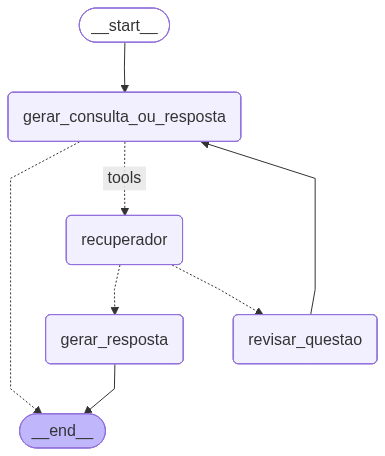

In [23]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

## 8. Executar o RAG agentic

In [24]:
def gerar_prompt_analise_itil(df: pd.DataFrame, idioma: str = 'pt', quantidade: int = 30) -> str:
    """
    Filtra um DataFrame de tickets por idioma e monta um prompt em lote
    para análise do motor cognitivo baseada na ITIL 4.

    Args:
        df (pd.DataFrame): O DataFrame contendo os tickets consolidados.
        idioma (str): O idioma desejado para o filtro (ex: 'pt', 'en'). Padrão é 'pt'.
        quantidade (int): O número máximo de tickets no prompt. Padrão é 30.

    Returns:
        str: O texto final do prompt formatado, ou None se nenhum ticket for encontrado.
    """
    # 1. Filtra o DataFrame original para trazer apenas os tickets do idioma escolhido
    df_filtrado = df[df['idioma'] == idioma]

    # 2. Verifica se o filtro retornou resultados
    if df_filtrado.empty:
        print(f"AVISO: Nenhum ticket no idioma '{idioma}' foi encontrado no dataset.")
        return None

    # 3. Define a quantidade de tickets
    # Garantimos que não vamos pedir mais do que o total disponível
    limite = min(quantidade, len(df_filtrado))

    # 4. Início do Prompt (Cabeçalho único)
    prompt_texto = "Por favor, analise os seguintes tickets aplicando as diretrizes da ITIL 4 estabelecidas:\n"
    prompt_texto += "Para cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente, caso não seja identificado pratica\n"
    prompt_texto += "---"

    # 5. Laço de repetição para percorrer o grupo de tickets
    for i in range(limite):
        ticket_atual = df_filtrado.iloc[i]

        # Adiciona as informações do ticket atual ao texto do prompt
        prompt_texto += f"""

Ticket #{ticket_atual['Id']}:
Assunto: {ticket_atual['assunto']}
Descricao: {ticket_atual['descricao']}
Solução: {ticket_atual['resposta']}
----------------------------------"""

    prompt_final = prompt_texto + "\nE retorne qual Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente."

    print(f"Sucesso! Prompt montado para um lote de {limite} tickets.")

    return prompt_final

In [25]:
import pandas as pd
from typing import List, Dict, Optional

In [26]:
# Carrega o arquivo df_tickets.csv para um DataFrame
caminho_csv = "amostra.csv"

if not os.path.exists(caminho_csv):
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_csv}")

df_tickets = pd.read_csv(caminho_csv)

print("✅ df_tickets carregado com sucesso!")
print(f"Linhas: {df_tickets.shape[0]} | Colunas: {df_tickets.shape[1]}")
display(df_tickets.head())

✅ df_tickets carregado com sucesso!
Linhas: 419 | Colunas: 10


,Id,assunto,fila,descricao,tipo,resposta,prioridade,todas_tags,idioma,descricao_length
0,3,Erro na Autocompletação de Código do IntelliJ ...,Technical Support,"Prezado Suporte ao Cliente <name>,\n\nEstou es...",Incident,"Prezado <name>,\n\nObrigado por entrar em cont...",high,"['Technical Support', 'Software Bug', 'Problem...",pt,740
1,25,Problemas intermitentes de exibição após atual...,Product Support,"Caro Suporte ao Cliente,\n\n Estou entrando em...",Problem,"Caro <name>,\n\n Obrigado por entrar em contat...",high,"['Technical Support', 'Product Support', 'Soft...",pt,975
2,42,Pedido de Assistência para Administração de Se...,Customer Service,"Prezado Suporte ao Cliente de Serviços de TI,\...",Request,"Prezado <name>,\n\nObrigado por entrar em cont...",medium,"['Technical Support', 'IT Support', 'Performan...",pt,1271
3,57,Urgente: Relato de Falha na Bateria do MacBook...,Returns and Exchanges,"Prezado Atendimento ao Cliente,<br><br>Recente...",Problem,"Prezado [Nome],<br><br>Lamento pelo inconvenie...",medium,"['Product Support', 'Hardware Failure', 'Retur...",pt,326
4,62,Assistência Necessária para Integração do Jira...,Technical Support,"Prezado Time de Suporte ao Cliente,\n\nEspero ...",Request,"Prezado <name>,\n\nObrigado por entrar em cont...",high,"['Technical Support', 'Product Support', 'Soft...",pt,1112


In [27]:
def gerar_prompt_excluindo_primeiros(df: pd.DataFrame, excluir: int = 1, idioma: str = 'pt', quantidade: int = 30) -> Optional[str]:
    """
    Gera o prompt a partir do df excluindo os primeiros `excluir` registros.
    """
    if excluir < 0:
        raise ValueError("excluir deve ser >= 0")
    df_slice = df.iloc[excluir:]
    if df_slice.empty:
        print(f"AVISO: Não há tickets após excluir os primeiros {excluir} registros.")
        return None
    # reutiliza a função já definida no notebook
    return gerar_prompt_analise_itil(df_slice, idioma=idioma, quantidade=quantidade)

In [28]:
prompt = gerar_prompt_analise_itil(df_tickets, idioma='pt', quantidade=5)

Sucesso! Prompt montado para um lote de 5 tickets.


In [29]:
def chamar_agent_stream(prompt_lote: str, caminho_md: str = "resposta_agent_rag.md") -> None:
    if not prompt_lote:
        print("Nao foi possivel gerar o prompt. Verifique os dados e tente novamente.")
        return

    import contextlib
    import io
    import os

    def _extrair_texto(valor):
        if isinstance(valor, str):
            return valor
        if isinstance(valor, list):
            partes = []
            for item in valor:
                if isinstance(item, dict):
                    partes.append(str(item.get("text") or item.get("content") or item))
                elif hasattr(item, "content"):
                    partes.append(str(item.content))
                else:
                    partes.append(str(item))
            return "\n".join(partes).strip()
        if isinstance(valor, dict):
            conteudo = valor.get("text") or valor.get("content") or valor
            return _extrair_texto(conteudo)
        if hasattr(valor, "content"):
            return _extrair_texto(valor.content)
        return str(valor)

    def _somente_tabela_markdown(texto):
        linhas = [linha.rstrip() for linha in str(texto).splitlines()]
        tabela = []
        capturando = False
        for linha in linhas:
            linha_strip = linha.strip()
            if linha_strip.startswith("|"):
                capturando = True
                tabela.append(linha_strip)
                continue
            if capturando and not linha_strip:
                continue
            if capturando:
                break
        return "\n".join(tabela).strip()

    print("Prompt gerado, chamando o agente...")

    entradas = {
        "messages": [
            {"role": "system", "content": instrucao},
            {"role": "user", "content": prompt_lote},
        ]
    }

    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        result = app.invoke(entradas)

    final_text = ""
    if isinstance(result, dict):
        mensagens = result.get("messages", [])
        if mensagens:
            final_text = _somente_tabela_markdown(_extrair_texto(mensagens[-1]))

    filename = os.path.join(os.getcwd(), caminho_md)
    arquivo_existente = os.path.exists(filename) and os.path.getsize(filename) > 0

    with open(filename, "a", encoding="utf-8") as f:
        if final_text:
            if arquivo_existente:
                f.write("\n\n")
            f.write(final_text)
            print(f"Resposta anexada em {filename}")
        else:
            fallback = _somente_tabela_markdown(buffer.getvalue().strip())
            if fallback:
                if arquivo_existente:
                    f.write("\n\n")
                f.write(fallback)
                print(f"Resposta (fallback) anexada em {filename}")
            else:
                print("Nenhuma resposta final foi gerada.")



def processar_lotes(
    df: pd.DataFrame,
    num_lote: int = 5,
    tamanho_lote: int = 30,
    idioma: str = 'pt',
    caminho_md: str = 'resposta_agent_rag.md',
    start_offset: int = 0,
) -> None:
    """Processa o DataFrame em lotes, podendo pular os primeiros `start_offset` registros."""
    if start_offset < 0:
        raise ValueError("start_offset deve ser >= 0")

    total_lotes = num_lote
    available = max(0, len(df) - start_offset)
    limite_total = min(available, total_lotes * tamanho_lote)

    if limite_total == 0:
        print("Nenhum ticket disponível para processamento em lotes.")
        return

    titulo = 'Respostas ITIL por Lote - RAG'
    with open(caminho_md, 'a', encoding='utf-8') as arquivo_md_saida:
        arquivo_md_saida.write(f'# {titulo}\n\n')

    processed_end = start_offset + limite_total

    for lote_numero in range(total_lotes):
        inicio = start_offset + lote_numero * tamanho_lote
        fim = inicio + tamanho_lote

        if inicio >= processed_end:
            print(f'Lote {lote_numero + 1}: nenhum ticket restante.')
            break

        prompt_lote = gerar_prompt_excluindo_primeiros(
            df,
            excluir=inicio,
            idioma=idioma,
            quantidade=tamanho_lote,
        )
        if not prompt_lote:
            print(f'Lote {lote_numero + 1}: prompt vazio, pulando.')
            continue

        print(f'Processando lote {lote_numero + 1}/{total_lotes} com tickets {inicio + 1} a {min(fim, processed_end)}...')
        chamar_agent_stream(prompt_lote, caminho_md=caminho_md)

In [30]:
# def chamar_agent_stream(prompt_lote: str, caminho_md: str = "resposta_agent_rag.md") -> None:
#     if not prompt_lote:
#         print("Nao foi possivel gerar o prompt. Verifique os dados e tente novamente.")
#         return

#     import contextlib
#     import io
#     import os

#     def _extrair_texto(valor):
#         if isinstance(valor, str):
#             return valor
#         if isinstance(valor, list):
#             partes = []
#             for item in valor:
#                 if isinstance(item, dict):
#                     partes.append(str(item.get("text") or item.get("content") or item))
#                 elif hasattr(item, "content"):
#                     partes.append(str(item.content))
#                 else:
#                     partes.append(str(item))
#             return "\n".join(partes).strip()
#         if isinstance(valor, dict):
#             conteudo = valor.get("text") or valor.get("content") or valor
#             return _extrair_texto(conteudo)
#         if hasattr(valor, "content"):
#             return _extrair_texto(valor.content)
#         return str(valor)

#     def _somente_tabela_markdown(texto):
#         linhas = [linha.rstrip() for linha in str(texto).splitlines()]
#         tabela = []
#         capturando = False
#         for linha in linhas:
#             linha_strip = linha.strip()
#             if linha_strip.startswith("|"):
#                 capturando = True
#                 tabela.append(linha_strip)
#                 continue
#             if capturando and not linha_strip:
#                 continue
#             if capturando:
#                 break
#         return "\n".join(tabela).strip()

#     print("Prompt gerado, chamando o agente...")

#     entradas = {
#         "messages": [
#             {"role": "system", "content": instrucao},
#             {"role": "user", "content": prompt_lote},
#         ]
#     }

#     buffer = io.StringIO()
#     with contextlib.redirect_stdout(buffer):
#         result = app.invoke(entradas)

#     final_text = ""
#     if isinstance(result, dict):
#         mensagens = result.get("messages", [])
#         if mensagens:
#             final_text = _somente_tabela_markdown(_extrair_texto(mensagens[-1]))

#     filename = os.path.join(os.getcwd(), caminho_md)
#     arquivo_existente = os.path.exists(filename) and os.path.getsize(filename) > 0

#     with open(filename, "a", encoding="utf-8") as f:
#         if final_text:
#             if arquivo_existente:
#                 f.write("\n\n")
#             f.write(final_text)
#             print(f"Resposta anexada em {filename}")
#         else:
#             fallback = _somente_tabela_markdown(buffer.getvalue().strip())
#             if fallback:
#                 if arquivo_existente:
#                     f.write("\n\n")
#                 f.write(fallback)
#                 print(f"Resposta (fallback) anexada em {filename}")
#             else:
#                 print("Nenhuma resposta final foi gerada.")



# def processar_lotes(
#     df: pd.DataFrame,
#     num_lote: int = 5,
#     tamanho_lote: int = 30,
#     idioma: str = 'pt',
#     caminho_md: str = 'resposta_agent_rag.md',
#     start_offset: int = 0,
# ) -> None:
#     """Processa o DataFrame em lotes, podendo pular os primeiros `start_offset` registros."""
#     if start_offset < 0:
#         raise ValueError("start_offset deve ser >= 0")

#     total_lotes = num_lote
#     available = max(0, len(df) - start_offset)
#     limite_total = min(available, total_lotes * tamanho_lote)

#     if limite_total == 0:
#         print("Nenhum ticket disponível para processamento em lotes.")
#         return

#     titulo = 'Respostas ITIL por Lote - RAG'
#     with open(caminho_md, 'a', encoding='utf-8') as arquivo_md_saida:
#         arquivo_md_saida.write(f'# {titulo}\n\n')

#     processed_end = start_offset + limite_total

#     for lote_numero in range(total_lotes):
#         inicio = start_offset + lote_numero * tamanho_lote
#         fim = inicio + tamanho_lote

#         if inicio >= processed_end:
#             print(f'Lote {lote_numero + 1}: nenhum ticket restante.')
#             break

#         prompt_lote = gerar_prompt_excluindo_primeiros(
#             df,
#             excluir=inicio,
#             idioma=idioma,
#             quantidade=tamanho_lote,
#         )
#         if not prompt_lote:
#             print(f'Lote {lote_numero + 1}: prompt vazio, pulando.')
#             continue

#         print(f'Processando lote {lote_numero + 1}/{total_lotes} com tickets {inicio + 1} a {min(fim, processed_end)}...')
#         chamar_agent_stream(prompt_lote, caminho_md=caminho_md)

In [ ]:
processar_lotes(
    df_tickets,
    num_lote=5,
    tamanho_lote=30,
    idioma='pt',
    caminho_md='resposta_agent_rag.md'
    ,start_offset=150
    )

Sucesso! Prompt montado para um lote de 30 tickets.
Processando lote 1/5 com tickets 151 a 180...
Prompt gerado, chamando o agente...


Resposta anexada em c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\resposta_agent_rag.md
Sucesso! Prompt montado para um lote de 30 tickets.
Processando lote 2/5 com tickets 181 a 210...
Prompt gerado, chamando o agente...
Resposta anexada em c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\resposta_agent_rag.md
Sucesso! Prompt montado para um lote de 30 tickets.
Processando lote 3/5 com tickets 211 a 240...
Prompt gerado, chamando o agente...
Resposta anexada em c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\resposta_agent_rag.md
Sucesso! Prompt montado para um lote de 30 tickets.
Processando lote 4/5 com tickets 241 a 270...
Prompt gerado, chamando o agente...
Resposta anexada em c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\resposta_agent_rag.md
Sucesso! Prompt montado para um lote de 30 tickets.
Processando lote 5/5 com tickets 271 a 300...
Prompt gerado, chamando o agente...


In [ ]:
# chamar_agent_stream()